<a href="https://colab.research.google.com/github/csajama-oss/data_science_utn_clusterai2026_Sajama/blob/main/clusterai_Carla_Sajama_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Trabajo Final Grupal**: AIRBNB Price - Exploratory Data Analysis

**Universidad Tecnológica Nacional, Buenos Aires**
**Ingeniería Industrial**

**Ciencia de Datos - Curso I5571**

**LIBRERIAS**

In [1]:
# Importo librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Buscamos saber la cantidad de Filas y Columnas del dataset

df = pd.read_csv("airbnb_us.csv")

print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

df.head()

Cantidad de filas: 19309
Cantidad de columnas: 29


,id,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,...,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds,price
0,13418779,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,flexible,True,SF,...,-122.431619,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.0,2.0,750.0
1,3808709,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.0,Real Bed,moderate,True,DC,...,-77.034596,Great studio in midtown DC,Columbia Heights,4,40.0,NaN,20009,0.0,1.0,115.0
2,12422935,Apartment,Private room,"{TV,""Wireless Internet"",Heating,""Smoke detecto...",2,1.0,Real Bed,strict,True,SF,...,-122.429526,Comfort Suite San Francisco,Noe Valley,3,100.0,https://a0.muscache.com/im/pictures/82509143-4...,94131,1.0,1.0,85.0
3,180792,House,Private room,"{TV,""Cable TV"",""Wireless Internet"",""Pets live ...",2,1.0,Real Bed,moderate,True,SF,...,-122.501095,Cozy Garden Studio - Private Entry,Richmond District,159,99.0,https://a0.muscache.com/im/pictures/0ed6c128-7...,94121,1.0,1.0,120.0
4,2658946,Apartment,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",6,1.5,Real Bed,strict,True,DC,...,-77.031189,Charming 2 bdrm in trendy U/14th streets w/par...,U Street Corridor,13,89.0,NaN,20009,2.0,3.0,200.0


In [3]:
#Identificación de cada tipo de dato
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19309 entries, 0 to 19308
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      19309 non-null  int64  
 1   property_type           19309 non-null  object 
 2   room_type               19309 non-null  object 
 3   amenities               19309 non-null  object 
 4   accommodates            19309 non-null  int64  
 5   bathrooms               19274 non-null  float64
 6   bed_type                19309 non-null  object 
 7   cancellation_policy     19309 non-null  object 
 8   cleaning_fee            19309 non-null  bool   
 9   city                    19309 non-null  object 
 10  description             19309 non-null  object 
 11  first_review            15355 non-null  object 
 12  host_has_profile_pic    19306 non-null  object 
 13  host_identity_verified  19306 non-null  object 
 14  host_response_rate      15013 non-null

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,19309.0,1.121819e+07,6.105064e+06,941.000000,6.211289e+06,1.215601e+07,1.639470e+07,2.121545e+07
accommodates,19309.0,3.426485e+00,2.204776e+00,1.000000,2.000000e+00,3.000000e+00,4.000000e+00,1.600000e+01
bathrooms,19274.0,1.276201e+00,5.867133e-01,0.000000,1.000000e+00,1.000000e+00,1.500000e+00,8.000000e+00
latitude,19309.0,3.972335e+01,1.902391e+00,37.704743,3.778427e+01,3.891502e+01,4.192686e+01,4.239044e+01
longitude,19309.0,-9.313568e+01,2.134489e+01,-122.511500,-1.224134e+02,-8.762574e+01,-7.699888e+01,-7.098505e+01
number_of_reviews,19309.0,2.508670e+01,4.434838e+01,0.000000,1.000000e+00,7.000000e+00,2.800000e+01,5.420000e+02
review_scores_rating,15175.0,9.472237e+01,7.097521e+00,20.000000,9.300000e+01,9.700000e+01,1.000000e+02,1.000000e+02
bedrooms,19292.0,1.361290e+00,9.012116e-01,0.000000,1.000000e+00,1.000000e+00,2.000000e+00,1.000000e+01
beds,19285.0,1.788800e+00,1.247000e+00,0.000000,1.000000e+00,1.000000e+00,2.000000e+00,1.600000e+01
price,19309.0,1.952255e+02,2.021842e+02,10.000000,8.700000e+01,1.350000e+02,2.200000e+02,1.999000e+03


**LIMPIEZA DE DATOS**

In [5]:
# Verificamos si existen registros duplicados
duplicados = df.duplicated().sum()

print("Cantidad de registros duplicados:", duplicados)

# Eliminamos duplicados únicamente si existen
if duplicados > 0:
    df = df.drop_duplicates().copy()

Cantidad de registros duplicados: 0


In [6]:
#Identificamos que cantidad de datos son nulos y el porcentaje de faltante
nulos = pd.DataFrame({
    'Cantidad de nulos': df.isnull().sum(),
    'Porcentaje (%)': (
        df.isnull().mean() * 100
    ).round(2)
})

nulos = nulos[nulos['Cantidad de nulos'] > 0]

nulos.sort_values(
    'Porcentaje (%)',
    ascending=False
)


,Cantidad de nulos,Porcentaje (%)
host_response_rate,4296,22.25
review_scores_rating,4134,21.41
first_review,3954,20.48
last_review,3954,20.48
thumbnail_url,2402,12.44
neighbourhood,1458,7.55
zipcode,225,1.17
bathrooms,35,0.18
beds,24,0.12
bedrooms,17,0.09


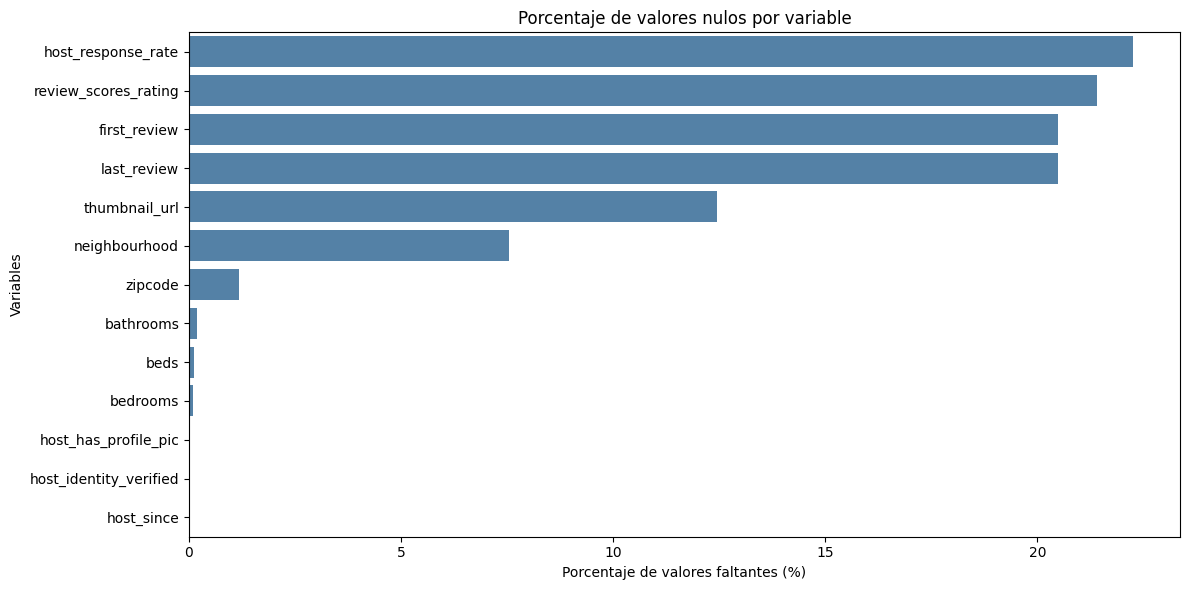

In [7]:
nulos_ordenados = nulos.sort_values(
    'Porcentaje (%)',
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=nulos_ordenados.reset_index(),
    x='Porcentaje (%)',
    y='index',
    color='steelblue'
)

plt.title('Porcentaje de valores nulos por variable')
plt.xlabel('Porcentaje de valores faltantes (%)')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()


In [8]:
#elimino las variables que no son necesarias para el análisis
#Id(identificacion), thumbnail_url(URL de imagen),name(nombre del anuncio),zipcode(ya tengo el dato de barrio y ciudad)
#first review(no hay relación con el precio), last review(poca relación con precio) & description(mucha información)
df.drop(['id','thumbnail_url','name','zipcode','first_review','last_review','description'],axis=1,inplace=True)

In [9]:
#verifico si se eliminaron correctamente
print(df.columns)

Index(['property_type', 'room_type', 'amenities', 'accommodates', 'bathrooms',
       'bed_type', 'cancellation_policy', 'cleaning_fee', 'city',
       'host_has_profile_pic', 'host_identity_verified', 'host_response_rate',
       'host_since', 'instant_bookable', 'latitude', 'longitude',
       'neighbourhood', 'number_of_reviews', 'review_scores_rating',
       'bedrooms', 'beds', 'price'],
      dtype='object')


In [10]:
#Ciudades que tiene la columna "CITY" para verificar que todas sean de USA
df['city'].unique()

array(['SF', 'DC', 'Chicago', 'Boston'], dtype=object)

In [11]:
#Análisis de "PRICE"- la variable más importante para analizar
df['price'].describe()

,price
count,19309.000000
mean,195.225542
std,202.184231
min,10.000000
25%,87.000000
50%,135.000000
75%,220.000000
max,1999.000000


Se visualiza que la media es mayor que la mediana. Hay propiedades caras que empujan el promedio hacia arriba.

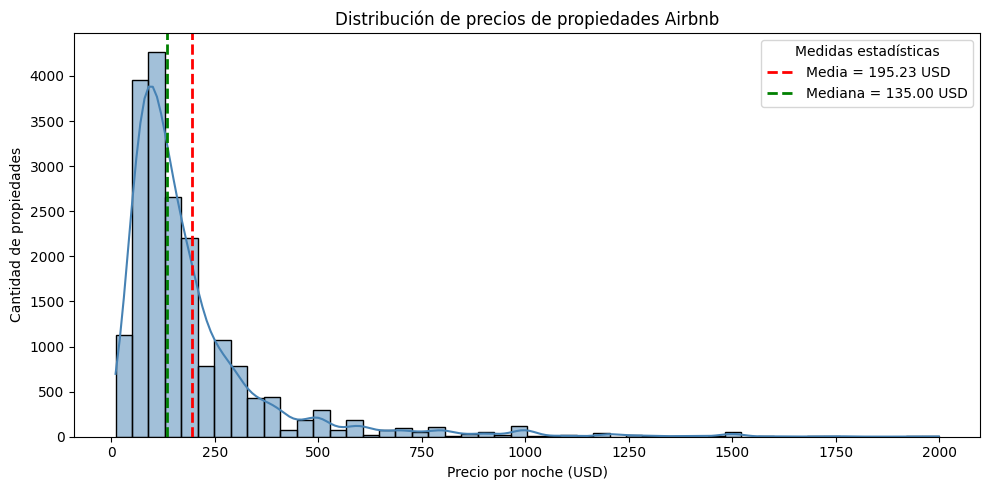

In [12]:
# Visualización de distribución de precios
import matplotlib.pyplot as plt
import seaborn as sns

media = df['price'].mean()
mediana = df['price'].median()

plt.figure(figsize=(10,5))

sns.histplot(
    df['price'],
    bins=50,
    kde=True,
    color='steelblue'
)

# Línea de la media
plt.axvline(
    media,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Media = {media:.2f} USD'
)

# Línea de la mediana
plt.axvline(
    mediana,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f'Mediana = {mediana:.2f} USD'
)

plt.title('Distribución de precios de propiedades Airbnb')
plt.xlabel('Precio por noche (USD)')
plt.ylabel('Cantidad de propiedades')
plt.legend(title='Medidas estadísticas')

plt.tight_layout()
plt.show()

El histograma muestra que la distribución no es normal
Las propiedades se encuentran aproximadamente entre 50 y 250 USD
El precio máximo se extiende hasta 2000 USD

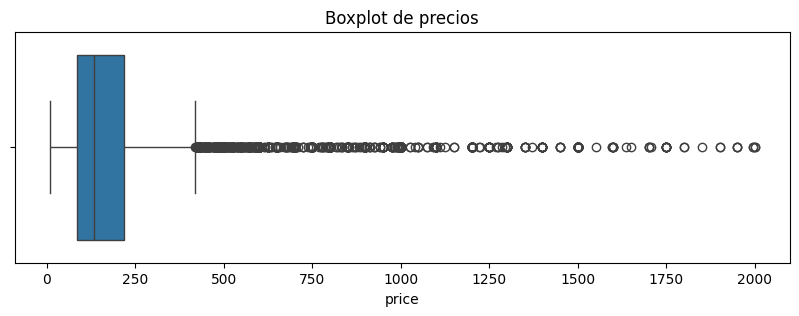

In [13]:
plt.figure(figsize=(10,3))

sns.boxplot(x=df['price'])

plt.title('Boxplot de precios')

plt.show()

l Boxplot muestra que hay valores atípicos. Se puede suponer que son caros por ser propiedades más lujosas, con más habitaciones, entre otras.

In [14]:
# Detección de outliers mediante IQR

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[
    (df['price'] < limite_inferior) |
    (df['price'] > limite_superior)
]['price']

print(f"Primer cuartil (Q1): {Q1:.2f}")
print(f"Tercer cuartil (Q3): {Q3:.2f}")
print(f"Rango intercuartílico (IQR): {IQR:.2f}")
print(f"Límite inferior: {limite_inferior:.2f}")
print(f"Límite superior: {limite_superior:.2f}")
print(f"Cantidad de outliers: {len(outliers)}")
print(f"Porcentaje de outliers: {len(outliers)/len(df)*100:.2f}%")

Primer cuartil (Q1): 87.00
Tercer cuartil (Q3): 220.00
Rango intercuartílico (IQR): 133.00
Límite inferior: -112.50
Límite superior: 419.50
Cantidad de outliers: 1570
Porcentaje de outliers: 8.13%


/tmp/ipykernel_5751/4008579632.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


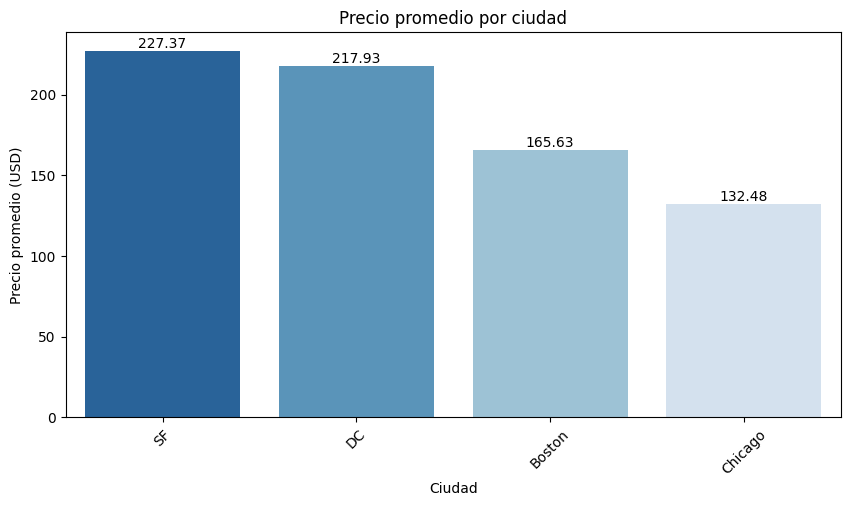

In [15]:
#Variables vs PRICE - La variable más importante
#City vs price
plt.figure(figsize=(10,5))

city_price = (
    df.groupby('city')['price']
      .mean()
      .sort_values(ascending=False)
      .reset_index()
)

ax = sns.barplot(
    data=city_price,
    x='city',
    y='price',
    palette='Blues_r'
)

# Mostrar valores sobre las barras
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Precio promedio por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Precio promedio (USD)')
plt.xticks(rotation=45)

plt.show()

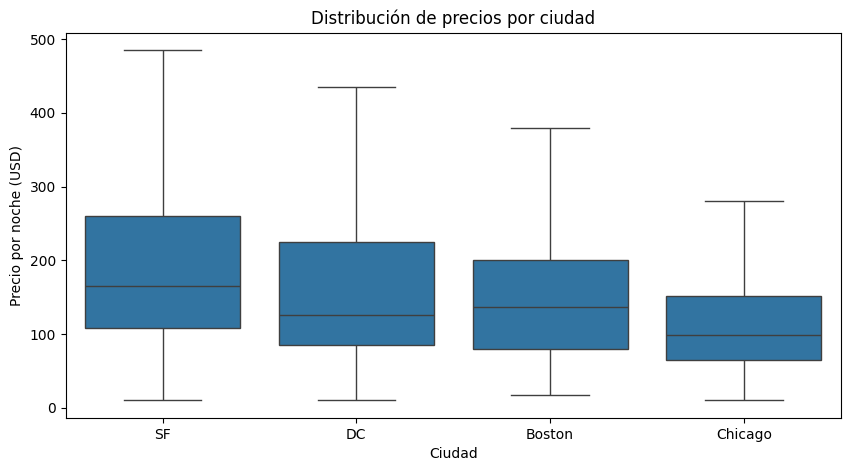

In [16]:
plt.figure(figsize=(10,5))

orden = (
    df.groupby('city')['price']
      .mean()
      .sort_values(ascending=False)
      .index
)

sns.boxplot(
    data=df,
    x='city',
    y='price',
    order=orden,
    showfliers=False
)

plt.title('Distribución de precios por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Precio por noche (USD)')

plt.show()

In [17]:
top_barrios = (
    df.groupby('neighbourhood')
      .agg(
          precio_promedio=('price', 'mean'),
          cantidad_propiedades=('price', 'count')
      )
      .query('cantidad_propiedades >= 20')
      .sort_values('precio_promedio', ascending=False)
      .head(10)
      .reset_index()
)

/tmp/ipykernel_5751/1851587307.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


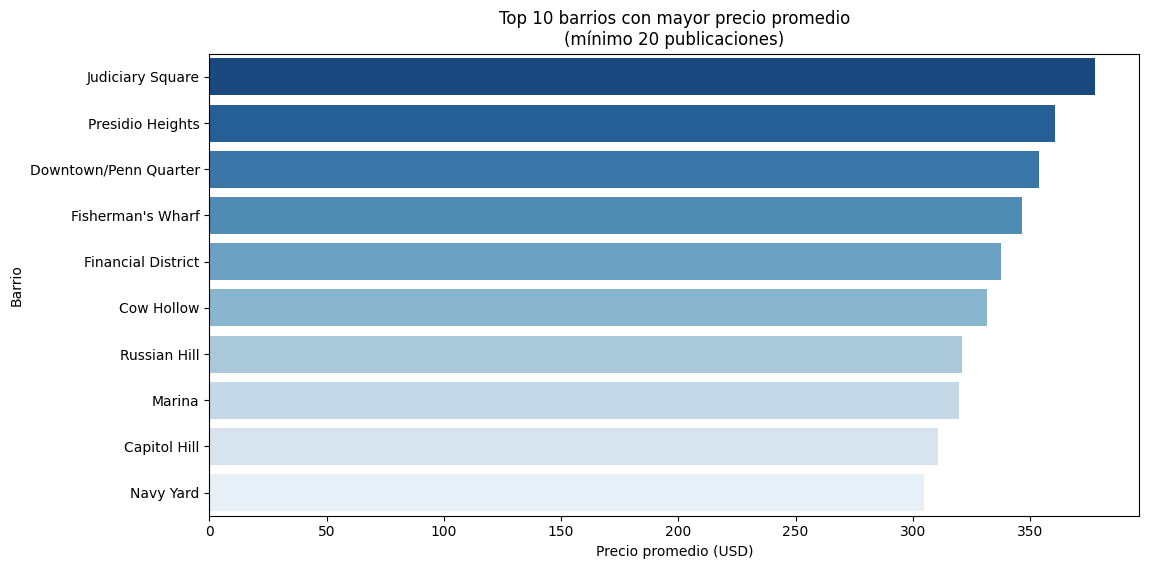

In [18]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_barrios,
    x='precio_promedio',
    y='neighbourhood',
    palette='Blues_r'
)

plt.title('Top 10 barrios con mayor precio promedio\n(mínimo 20 publicaciones)')
plt.xlabel('Precio promedio (USD)')
plt.ylabel('Barrio')

plt.show()

/tmp/ipykernel_5751/1537612618.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


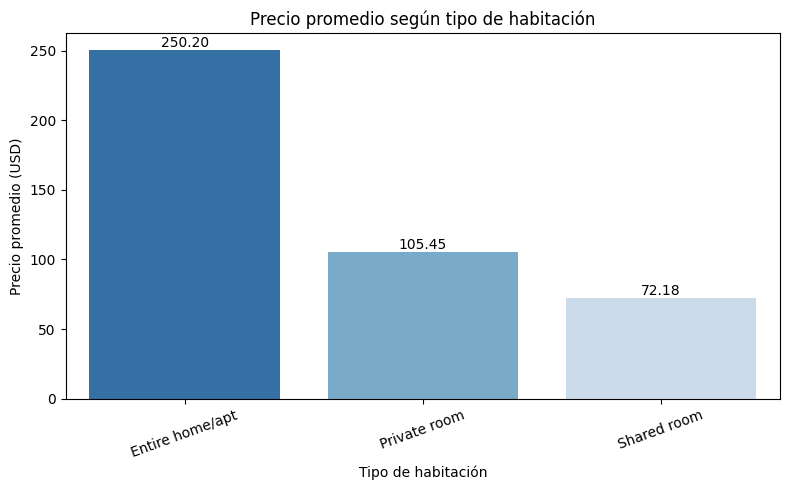

In [19]:
# Room type vs price - Precio promedio según tipo de habitación

room_price = (
    df.groupby('room_type')['price']
      .mean()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=room_price,
    x='room_type',
    y='price',
    palette='Blues_r'
)

# Mostrar valores sobre las barras
for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title('Precio promedio según tipo de habitación')
plt.xlabel('Tipo de habitación')
plt.ylabel('Precio promedio (USD)')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

/tmp/ipykernel_5751/2025199854.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


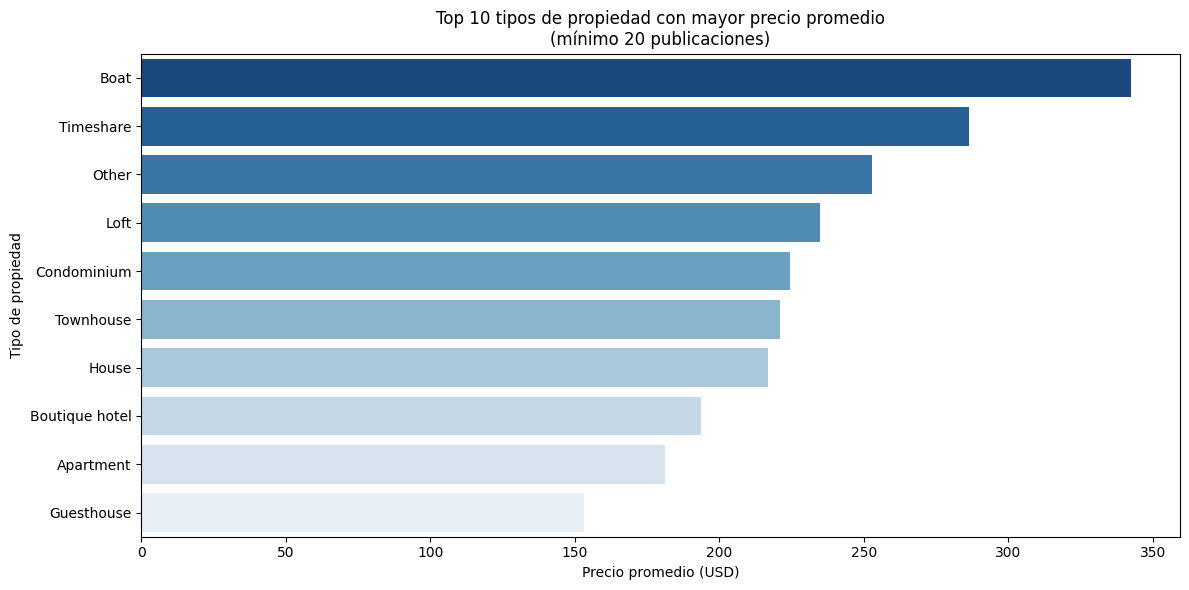

In [20]:
# Property type vs price - mínimo 20 publicaciones

property_price = (
    df.groupby('property_type')
      .agg(
          precio_promedio=('price', 'mean'),
          cantidad_propiedades=('price', 'count')
      )
      .query('cantidad_propiedades >= 20')
      .sort_values('precio_promedio', ascending=False)
      .head(10)
      .reset_index()
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=property_price,
    x='precio_promedio',
    y='property_type',
    palette='Blues_r'
)

plt.title('Top 10 tipos de propiedad con mayor precio promedio\n(mínimo 20 publicaciones)')
plt.xlabel('Precio promedio (USD)')
plt.ylabel('Tipo de propiedad')

plt.tight_layout()
plt.show()

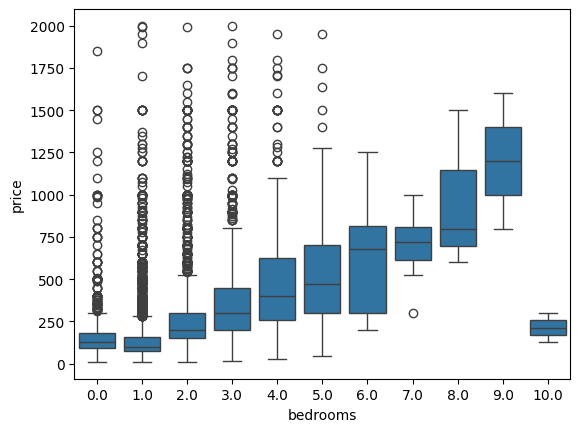

In [21]:
#Bedrooms vs price ---- A MEDIDA QUE AUMENTAN LOS DORMITORIOS AUMENTAN LOS PRECIOS?
sns.boxplot(
    data=df,
    x='bedrooms',
    y='price'
)

plt.show()

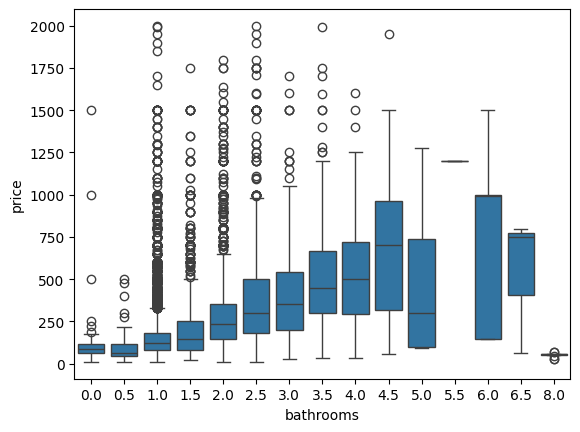

In [22]:
#Bathrooms vs price
sns.boxplot(
    data=df,
    x='bathrooms',
    y='price'
)

plt.show()

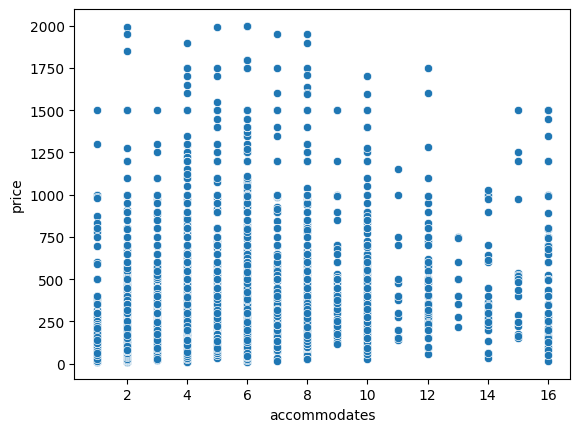

In [23]:
#Accomodates vs price
sns.scatterplot(
    data=df,
    x='accommodates',
    y='price'
)

plt.show()

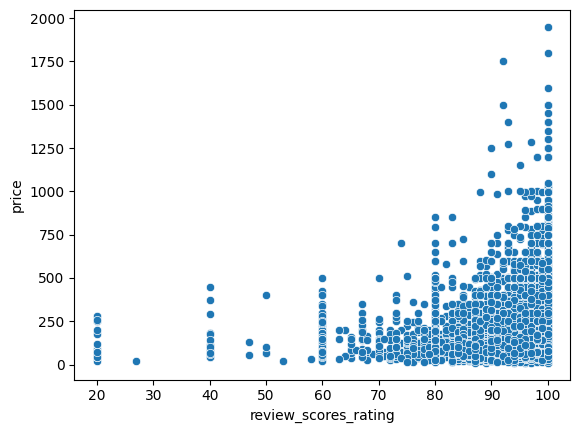

In [24]:
#Review score vs price - Se puede ver una concentración entre buenas calificaciones y precios menor a 1000
sns.scatterplot(
    data=df,
    x='review_scores_rating',
    y='price'
)

plt.show()

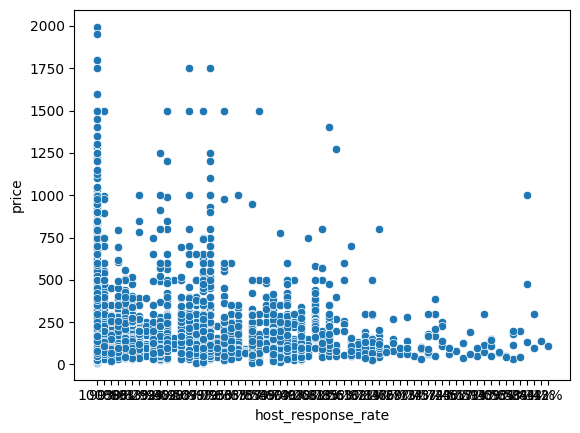

In [25]:
#Host response vs price
sns.scatterplot(
    data=df,
    x='host_response_rate',
    y='price'
)

plt.show()

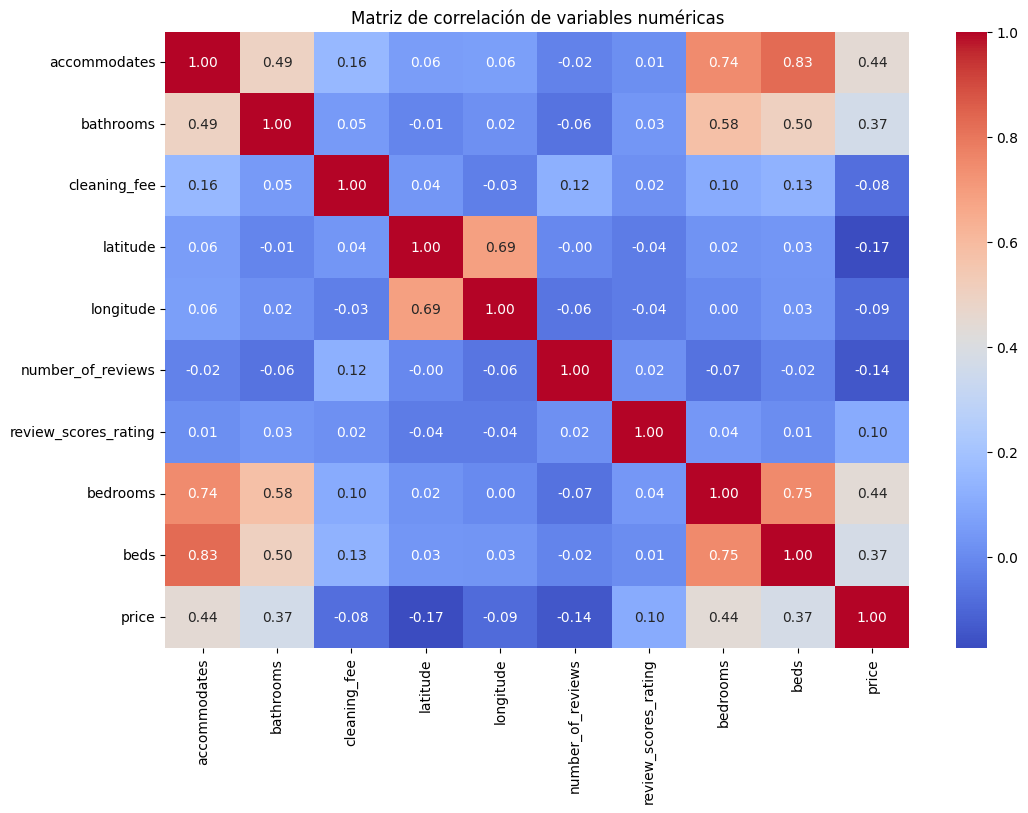

In [26]:
#Correlaciones-PARA SABER CUALES SON LAS VARIABLES NUMÉRICAS MAS RELACIONADAS CON EL
plt.figure(figsize=(12,8))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de correlación de variables numéricas')

plt.show()

Las variables accommodates, bedrooms, beds y bathrooms presentan las correlaciones positivas más altas con price, lo que sugiere que las características relacionadas con el tamaño y capacidad de la propiedad tienen una influencia significativa sobre el precio. Por otro lado, variables como review_scores_rating y host_response_rate muestran una relación más débil con la variable objetivo.

**CONCLUSION**

La variable PRICE presenta una distribución asimétrica positiva. El precio promedio de las propiedades es de 195 USD, la mediana es de 135 USD, lo que evidencia la existencia de propiedades con precios elevados que aumentan el promedio general. El 50% central de las publicaciones presenta precios entre 87 y 220 USD. El análisis exploratorio mostró que el precio de las propiedades está influenciado principalmente por la ubicación (ciudad y barrio) y por las características del alojamiento, como la capacidad, la cantidad de dormitorios, camas y baños. En resumen, las variables relacionadas con el tamaño y la ubicación de la propiedad presentan el mayor potencial predictivo para los modelos de machine learning.